In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("raddar/chest-xrays-indiana-university")

print("Path to dataset files:", path)

KeyboardInterrupt: 

In [ ]:
import shutil
import os

# 1. تحديد مكان الحفظ على جوجل درايف بتاعك
destination_path = '/content/drive/MyDrive/InnoTech_Dataset'
os.makedirs(destination_path, exist_ok=True)

shutil.copytree(path, destination_path, dirs_exist_ok=True)

'/content/drive/MyDrive/InnoTech_Dataset'

In [ ]:
import os

drive_folder = '/content/drive/MyDrive/InnoTech_Dataset'

# Check if the folder exists on Google Drive and list its contents
if os.path.exists(drive_folder):
    print("✅ The folder exists on Google Drive. Contents:")
    print(os.listdir(drive_folder))

    images_path = os.path.join(drive_folder, 'images')
    if os.path.exists(images_path):
        print("📁 Contents of the 'images' folder:", os.listdir(images_path))
else:
    print("⏳ Transfer is still in progress, please wait a moment...")

✅ The folder exists on Google Drive. Contents:
['indiana_projections.csv', 'images', 'indiana_reports.csv']
📁 Contents of the 'images' folder: ['images_normalized']


In [2]:
import pandas as pd, os

base = "/content/drive/MyDrive/InnoTech_Dataset"
img_dir = f"{base}/images/images_normalized"

proj = pd.read_csv(f"{base}/indiana_projections.csv")
rep = pd.read_csv(f"{base}/indiana_reports.csv")

print(proj.columns.tolist())
print(rep.columns.tolist())
print(proj.shape, rep.shape)

print(proj["projection"].value_counts())

files = set(os.listdir(img_dir))
print("Images in folder:", len(files))
print("CSV filenames found in folder:", proj["filename"].isin(files).sum(), "out of", len(proj))

proj.head()

['uid', 'filename', 'projection']
['uid', 'MeSH', 'Problems', 'image', 'indication', 'comparison', 'findings', 'impression']
(7466, 3) (3851, 8)
projection
Frontal    3818
Lateral    3648
Name: count, dtype: int64
Images in folder: 7470
CSV filenames found in folder: 7466 out of 7466


,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal
3,2,2_IM-0652-2001.dcm.png,Lateral
4,3,3_IM-1384-1001.dcm.png,Frontal


In [3]:
print('--- Reports Data Preview ---')
display(rep.head(3))

--- Reports Data Preview ---


,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.
2,3,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p..."


In [4]:
print('\n--- Projections Data Preview ---')
display(proj.head(3))


--- Projections Data Preview ---


,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal


In [5]:
rag = rep[["uid", "findings", "impression"]].copy()

rag = rag.dropna(subset=["findings", "impression"], how="all")

rag = rag.fillna("")

for col in ["findings", "impression"]:
    rag[col] = rag[col].str.strip()

rag["text"] = "Findings: " + rag["findings"] + " Impression: " + rag["impression"]

print("Reports kept:", len(rag), "out of", len(rep))
print(rag["text"].iloc[0])

rag.to_csv(f"{base}/rag_data.csv", index=False)

Reports kept: 3826 out of 3851
Findings: The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Impression: Normal chest x-XXXX.


In [6]:
# Show the first 2 rows of the file
rag.head(2)

,uid,findings,impression,text
0,1,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.,Findings: The cardiac silhouette and mediastin...
1,2,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.,Findings: Borderline cardiomegaly. Midline ste...


In [7]:
for i in range(2):
    print("uid:", rag["uid"].iloc[i])
    print(rag["text"].iloc[i])
    print("-" * 50)

uid: 1
Findings: The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Impression: Normal chest x-XXXX.
--------------------------------------------------
uid: 2
Findings: Borderline cardiomegaly. Midline sternotomy XXXX. Enlarged pulmonary arteries. Clear lungs. Inferior XXXX XXXX XXXX. Impression: No acute pulmonary findings.
--------------------------------------------------


In [8]:
check = pd.read_csv(f"{base}/rag_data.csv")

print("Rows:", len(check))

print(check.isna().sum())

print("Duplicate uids:", check["uid"].duplicated().sum())

print("Empty text:", (check["text"].str.strip() == "").sum())

check.head(2)

Rows: 3826
uid             0
findings      489
impression      6
text            0
dtype: int64
Duplicate uids: 0
Empty text: 0


,uid,findings,impression,text
0,1,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.,Findings: The cardiac silhouette and mediastin...
1,2,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.,Findings: Borderline cardiomegaly. Midline ste...


# CNN File

In [9]:
frontal = proj[proj["projection"] == "Frontal"]

df = frontal.merge(rep, on="uid")
print("Rows after merge:", df.shape)

print(df["Problems"].value_counts().head(10))

# Count missing values in Problems
print("Missing Problems:", df["Problems"].isna().sum())

Rows after merge: (3818, 10)
Problems
normal                 1387
No Indexing              91
Lung                     86
Calcified Granuloma      81
Thoracic Vertebrae       58
Calcinosis               40
Spine                    39
Opacity                  34
Cardiomegaly             28
Scoliosis                28
Name: count, dtype: int64
Missing Problems: 0


In [10]:
df = df[df["Problems"] != "No Indexing"].copy()

df["label"] = (df["Problems"].str.strip().str.lower() != "normal").astype(int)

print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(2))

cnn = df[["uid", "filename", "projection", "label", "Problems"]]
cnn.to_csv(f"{base}/cnn_data.csv", index=False)

label
1    2340
0    1387
Name: count, dtype: int64
label
1    0.63
0    0.37
Name: proportion, dtype: float64


In [11]:
cnn.head(3)

,uid,filename,projection,label,Problems
0,1,1_IM-0001-4001.dcm.png,Frontal,0,normal
1,2,2_IM-0652-1001.dcm.png,Frontal,1,Cardiomegaly;Pulmonary Artery
2,3,3_IM-1384-1001.dcm.png,Frontal,0,normal


In [12]:
cnn.tail(2)

,uid,filename,projection,label,Problems
3816,3998,3998_IM-2048-1001.dcm.png,Frontal,0,normal
3817,3999,3999_IM-2049-1001.dcm.png,Frontal,0,normal


In [ ]:
cnn.head(7)

,uid,filename,projection,label,Problems
0,1,1_IM-0001-4001.dcm.png,Frontal,0,normal
1,2,2_IM-0652-1001.dcm.png,Frontal,1,Cardiomegaly;Pulmonary Artery
2,3,3_IM-1384-1001.dcm.png,Frontal,0,normal
3,4,4_IM-2050-1001.dcm.png,Frontal,1,"Pulmonary Disease, Chronic Obstructive;Bullous..."
4,5,5_IM-2117-1003002.dcm.png,Frontal,1,Osteophyte;Thickening;Lung
5,6,6_IM-2192-1001.dcm.png,Frontal,0,normal
6,7,7_IM-2263-1001.dcm.png,Frontal,1,Pulmonary Atelectasis;Spondylosis;Arthritis


In [ ]:
cnn['Problems']

,Problems
0,normal
1,Cardiomegaly;Pulmonary Artery
2,normal
3,"Pulmonary Disease, Chronic Obstructive;Bullous..."
4,Osteophyte;Thickening;Lung
...,...
3813,Lung;Diaphragm;Cicatrix;Pulmonary Atelectasis;...
3814,Spine
3815,Opacity;Granuloma
3816,normal


In [13]:
cnn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3727 entries, 0 to 3817
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   uid         3727 non-null   int64 
 1   filename    3727 non-null   object
 2   projection  3727 non-null   object
 3   label       3727 non-null   int64 
 4   Problems    3727 non-null   object
dtypes: int64(2), object(3)
memory usage: 174.7+ KB


In [14]:
cnn = cnn.reset_index(drop=True)

In [ ]:
cnn.tail(2)

,uid,filename,projection,label,Problems
3725,3998,3998_IM-2048-1001.dcm.png,Frontal,0,normal
3726,3999,3999_IM-2049-1001.dcm.png,Frontal,0,normal


In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

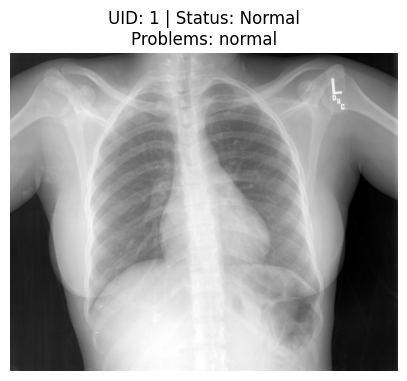

----------------------------------------
Medical Report (UID: 1):
Findings: The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Impression: Normal chest x-XXXX.
----------------------------------------


In [ ]:
def show_patient(uid, cnn_df, rag_df, images_folder):
    row = cnn_df[cnn_df['uid'] == uid].iloc[0]
    filename = row['filename']
    label = "Abnormal" if row['label'] == 1 else "Normal"
    problems = row['Problems']

    text = rag_df[rag_df['uid'] == uid]['text'].values[0]

    img = cv2.imread(os.path.join(images_folder, filename), cv2.IMREAD_GRAYSCALE)
    plt.figure(figsize=(5, 5))
    plt.imshow(img, cmap='gray')
    plt.title(f"UID: {uid} | Status: {label}\nProblems: {problems}")
    plt.axis('off')
    plt.show()

    print("-" * 40)
    print(f"Medical Report (UID: {uid}):\n{text}")
    print("-" * 40)


show_patient(1, cnn, check, "/content/drive/MyDrive/InnoTech_Dataset/images/images_normalized")

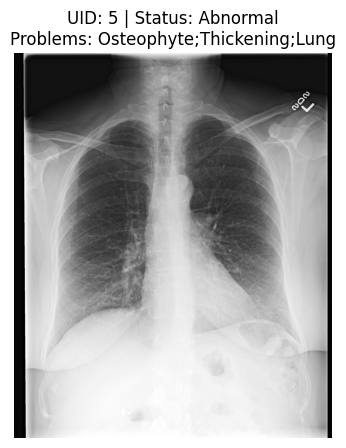

----------------------------------------
Medical Report (UID: 5):
Findings: The cardiomediastinal silhouette and pulmonary vasculature are within normal limits. There is no pneumothorax or pleural effusion. There are no focal areas of consolidation. Cholecystectomy clips are present. Small T-spine osteophytes. There is biapical pleural thickening, unchanged from prior. Mildly hyperexpanded lungs. Impression: No acute cardiopulmonary abnormality.
----------------------------------------


In [ ]:
show_patient(5, cnn, check, "/content/drive/MyDrive/InnoTech_Dataset/images/images_normalized")

In [15]:
from sklearn.model_selection import train_test_split

# Split patients (uid), not images
uids = cnn["uid"].unique()
train_u, temp_u = train_test_split(uids, test_size=0.3, random_state=42)
val_u, test_u = train_test_split(temp_u, test_size=0.5, random_state=42)

train_set, val_set = set(train_u), set(val_u)

def get_split(u):
    if u in train_set:
        return "train"
    if u in val_set:
        return "val"
    return "test"

cnn["split"] = cnn["uid"].apply(get_split)

# Check sizes and label balance in each split
print(cnn["split"].value_counts())
print(cnn.groupby("split")["label"].mean().round(2))

cnn.to_csv(f"{base}/cnn_data.csv", index=False)

split
train    2601
test      569
val       557
Name: count, dtype: int64
split
test     0.62
train    0.63
val      0.61
Name: label, dtype: float64


In [16]:
import cv2, os
from tqdm import tqdm

src_dir = f"{base}/images/images_normalized"
dst_dir = f"{base}/images_224"
os.makedirs(dst_dir, exist_ok=True)

for fname in tqdm(cnn["filename"]):
    dst = os.path.join(dst_dir, fname)
    if os.path.exists(dst):          # skip images already done
        continue
    img = cv2.imread(os.path.join(src_dir, fname), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)   # 3 channels
    cv2.imwrite(dst, img)

# Add the new image path to the CSV
cnn["path"] = dst_dir + "/" + cnn["filename"]
cnn.to_csv(f"{base}/cnn_data.csv", index=False)

print("Resized images:", len(os.listdir(dst_dir)))

100%|██████████| 3727/3727 [40:10<00:00,  1.55it/s]


Resized images: 3727
